# **Turning our models into Multi-Feature Models — Budget + IMDb Ratings & Votes**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

In my previous model defining notebooks, training **Linear Regression**, **Decision Tree**, and **Random Forest** on production `budget` alone hit a clear performance ceiling (~42%–45% $R^2$) because budget by itself cannot distinguish breakout word-of-mouth hits from big-budget flops.

In this notebook, I load my merged dataset containing **IMDb ratings and vote counts**, retrain all three models on the exact same `random_state=42` 80/20 split, compare their accuracy jump, and export `linearregression_v2.json`, `decisiontree_v2.json`, and `randomforest_v2.json` for the portfolio website.

### **Step 1 - Linear Regression v2 Data Exploration**

I load the merged dataset, print the available column names to verify the IMDb rating and vote columns, and inspect the dataset size and missing values before training.

In [4]:
import matplotlib.pyplot as plot
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pand

# load the dataset
movies = pand.read_csv("movies.csv")

print("Total:", len(movies))
print()
columns = ["budget", "averageRating", "numVotes", "revenue"]

print("Missing values per column:")
for c in columns:
  missingcount = movies[c].isnull().sum()
  print(c + ":", missingcount)
print()
print(movies[["budget", "averageRating", "numVotes", "revenue"]].describe())

Total: 902

Missing values per column:
budget: 0
averageRating: 0
numVotes: 0
revenue: 0

             budget  averageRating      numVotes       revenue
count  9.020000e+02     902.000000  9.020000e+02  9.020000e+02
mean   8.452772e+07       7.149446  4.682119e+05  3.589842e+08
std    8.097168e+07       0.937263  4.539463e+05  3.916373e+08
min    3.500000e+04       2.200000  4.570000e+02  5.524000e+04
25%    1.900000e+07       6.500000  1.565818e+05  7.750090e+07
50%    6.000000e+07       7.300000  3.382875e+05  2.398537e+08
75%    1.385000e+08       7.800000  6.518500e+05  5.047626e+08
max    6.588000e+08       9.300000  3.266584e+06  2.942650e+09


### **Step 2 - Data Preprocessing & Train/Test Split**

Now that I am using multiple input features, **Z-score standardisation** is essential because `budget`, `numVotes`, and `averageRating` are measured on different scales. Scaling every feature using the training set's mean and standard deviation puts all three inputs on an equal level. I use `random_state=42` so the 721 training movies and 181 testing movies match v1 identically.

In [5]:
from sklearn.model_selection import train_test_split

# define the 3 input features and singular target
features = ["budget", "averageRating", "numVotes"]
x = movies[features]
y = movies["revenue"]

# 80/20 split using random_state=42 to match v1
xtrainingset, xtestingset, ytrainingset, ytestingset = train_test_split( x, y, test_size=0.2, random_state=42)
mean = xtrainingset.mean()
stddev = xtrainingset.std()

xtrainingsetformulated = (xtrainingset - mean) / stddev
xtestingsetformulated = (xtestingset - mean) / stddev

print("Training movies:", len(xtrainingset))
print("Testing movies: ", len(xtestingset))

Training movies: 721
Testing movies:  181


### **Step 3 - Model Training**

I train a **Multiple Linear Regression** model on the training features. Unlike v1 which learned a single slope for `budget`, this model learns a separate coefficient for each input feature to combine production budget with IMDb ratings and vote counts.

In [7]:
from sklearn.linear_model import LinearRegression

# create and train the Multiple Linear Regression model
model = LinearRegression()
model.fit(xtrainingsetformulated, ytrainingset)

# print the base revenue and the learned weight for each feature
print("Intercept: $" + f"{model.intercept_:,.2f}")
print()

for i in range(len(features)):
  featurename = features[i]
  coef = round(model.coef_[i], 2)
  print("coefficient for", featurename + ":", coef)

Intercept: $358,513,481.90

coefficient for budget: 248693954.3
coefficient for averageRating: 15778940.65
coefficient for numVotes: 85978725.39


### **Step 4 - Model Evaluation**

I evaluate the v2 Linear Regression model on the 181 unseen testing movies using **MAE**, **RMSE**, and **$R^2$** so i can compare directly against the v1 budget-only baseline later in the website.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# generate predictions on the unseen scaled test set
pred = model.predict(xtestingsetformulated)

# calculate accuracy metrics
rmse = np.sqrt(mean_squared_error(ytestingset, pred))
r2 = r2_score(ytestingset, pred)
mae = mean_absolute_error(ytestingset, pred)

print("RMSE: $" + f"{rmse:,.2f}")
print("MAE:  $" + f"{mae:,.2f}")
print("R2:  ", round(r2, 4))

RMSE: $254,667,522.50
MAE:  $177,204,168.82
R2:   0.513


### **Step 5 - Visualising The Findings & Predictions**

I plot **Actual Revenue vs. Predicted Revenue** on the 181 test movies. The red line represents a perfect prediction. The closer the green dots cluster around that line, the more accurate the model's estimates are.

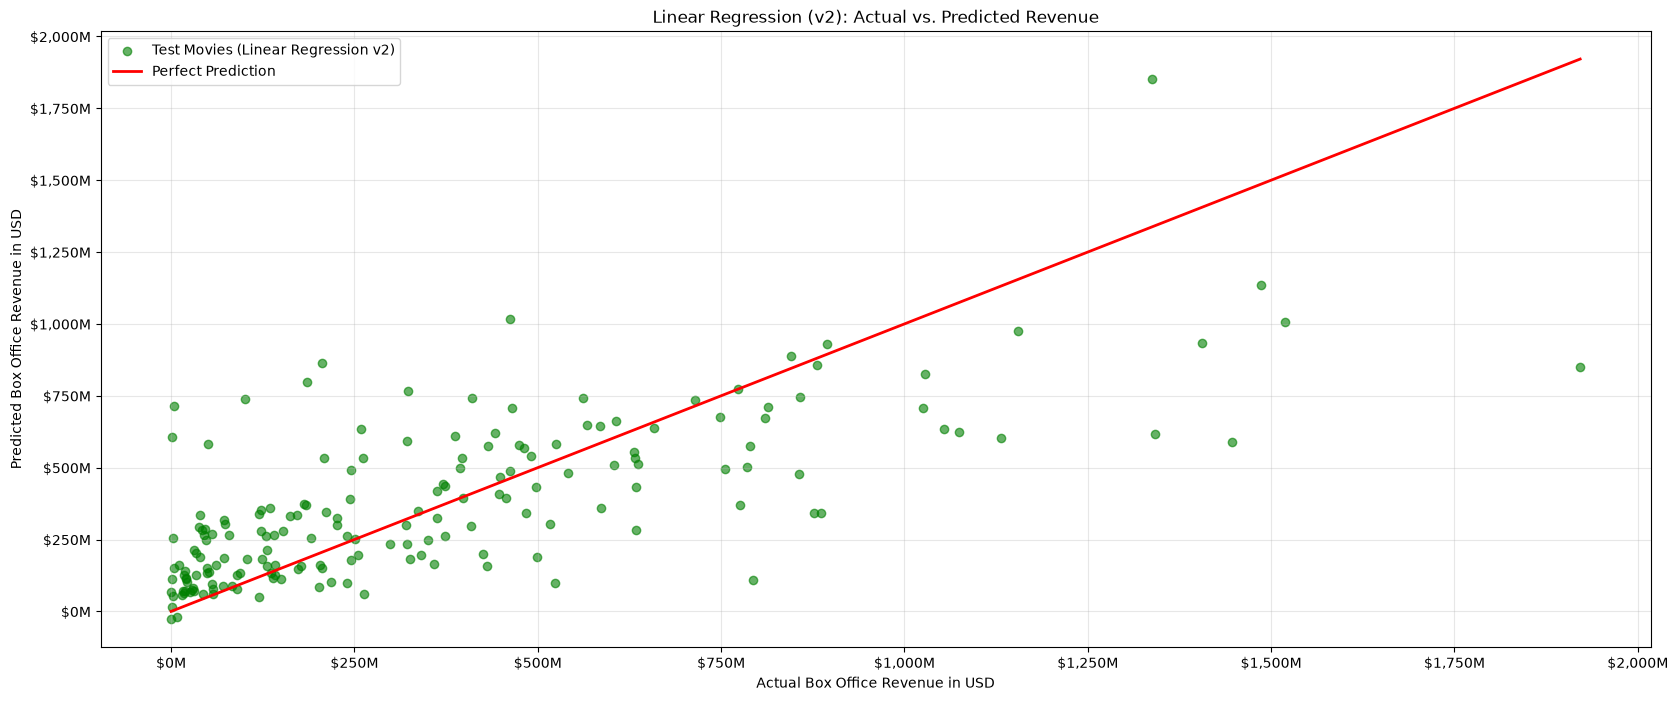

In [11]:
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(20, 8))
plot.scatter( ytestingset,pred,alpha=0.6,color="green",label="Test Movies (Linear Regression v2)",)

# draw a diagonal line showing where actual revenue equals predicted revenue
highest = max(ytestingset.max(), pred.max())
plot.plot([0, highest],[0, highest],color="red",linewidth=2,label="Perfect Prediction",)

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)
plot.xlabel("Actual Box Office Revenue in USD")
plot.ylabel("Predicted Box Office Revenue in USD")
plot.title("Linear Regression (v2): Actual vs. Predicted Revenue")
plot.legend()
plot.grid(True, alpha=0.3)
plot.show()

### **Step 6 - Export Data for the Website**

Finally, I can scale all 902 movies using the training mean and standard deviation, generate revenue predictions across the full dataset, and export everything to `linearregression_v2.json` so the portfolio website can compare v1 and v2 predictions side by side.

In [12]:
import json

# scale all 902 movies using the training mean and standard deviation before predicting
featurescaled = (movies[features] - mean) / stddev
everyprediction = model.predict(featurescaled)

allmovies = []

for i in range(len(movies)):
  iD = movies.iloc[i]
  pred = float(everyprediction[i])
  actual = float(iD["revenue"])

  if iD.name in xtestingset.index:
    splitlabel = "Testing"
  else:
    splitlabel = "Training"

  allmovies.append({
      "title": str(iD["title"]),
      "split": splitlabel,
      "budget": round(float(iD["budget"]), 0),
      "averageRating": round(float(iD["averageRating"]), 1),
      "numVotes": int(iD["numVotes"]),
      "actualrevenue": round(actual, 0),
      "predictedrevenue": round(pred, 0),
      "difference": round(actual - pred, 0),
  })

export = {
    "Model": "Linear Regression V2",
    "Features": features,
    "MAE": round(float(mae), 2),
    "RMSE": round(float(rmse), 2),
    "R2": round(float(r2), 4),
    "R2_percentage": round(float(r2) * 100, 1),
    "movies": allmovies,
}

with open("linearregression_v2.json", "w") as file:
  json.dump(export, file, indent=4)

# **Decision Tree Regression v2 - Movie Revenue**

Next, I train a **Decision Tree V2** using the exact same three input features (`budget`, `averageRating`, and `numVotes`) and the same 80/20 train/test split (`random_state=42`). Decision Trees split data using raw threshold rules (such as checking if `numVotes` is above a certain amount), so I pass the unscaled `xtrainingset` and `xtestingset` directly into the model.

### **Decision Tree (v2): Step 1 - Tuning & Model Training**

With three features instead of one, a Decision Tree can now combine `budget`, `averageRating`, and `numVotes` to separate breakout hits from big-budget flops. I test `max_depth` values again from `1` to `9` on the unseen test set to find the depth with the highest $R^2$ score before training the final model.

In [13]:
from sklearn.tree import DecisionTreeRegressor

# variables to keep track of the best depth and best score
bestdepth = 1
bestr2 = 0

# list of tree depths to test
depths = [1, 2, 3, 4, 5, 6, 7, 8]

for depth in depths:
  # create and train a decision tree with the current depth
  testtree = DecisionTreeRegressor(max_depth=depth, random_state=42)
  testtree.fit(xtrainingset, ytrainingset)

  # calculate R2 on both training and testing sets
  trainr2 = testtree.score(xtrainingset, ytrainingset)
  testr2 = testtree.score(xtestingset, ytestingset)

  print("Depth:", depth, "| Train R2:", round(trainr2, 4), "| Test R2:", round(testr2, 4))

  # save this depth if it beats our best test score so far
  if testr2 > bestr2:
    bestr2 = testr2
    bestdepth = depth

print()
print("Best depth:", bestdepth, "| Highest Test R2:", round(bestr2, 4))

Depth: 1 | Train R2: 0.3163 | Test R2: 0.3703
Depth: 2 | Train R2: 0.4316 | Test R2: 0.3719
Depth: 3 | Train R2: 0.5436 | Test R2: 0.4581
Depth: 4 | Train R2: 0.5952 | Test R2: 0.4755
Depth: 5 | Train R2: 0.6736 | Test R2: 0.3714
Depth: 6 | Train R2: 0.7424 | Test R2: 0.2703
Depth: 7 | Train R2: 0.7978 | Test R2: 0.3538
Depth: 8 | Train R2: 0.8661 | Test R2: 0.0061

Best depth: 4 | Highest Test R2: 0.4755


Now that I know the best depth to work with is 4, ill fit the model following that finding.

In [16]:
model2 = DecisionTreeRegressor(max_depth=bestdepth, random_state=42)
model2.fit(xtrainingset, ytrainingset);
print("Trained")

Trained


### **Step 2 - Model Evaluation**

I evaluate the trained Decision Tree v2 on the same 181 unseen testing movies the previous models used using **MAE**, **RMSE**, and **$R^2$**, and check how heavily the tree relied on `budget`, `averageRating`, and `numVotes` when making its splits.

In [18]:
# generate predictions on the unseen test set
pred2 = model2.predict(xtestingset)

# calculate accuracy metrics
mae2 = mean_absolute_error(ytestingset, pred2)
r22 = r2_score(ytestingset, pred2)
rmse2 = np.sqrt(mean_squared_error(ytestingset, pred2))


print("RMSE: $" + f"{rmse2:,.2f}")
print("MAE:  $" + f"{mae2:,.2f}")
print("R2:  ", round(r22, 4))
print("Tree Depth:", model2.get_depth())
print("Leaf Nodes:", model2.get_n_leaves())
print()

# print how much each feature contributed to the tree's decisions
print("Importance:")
for i in range(len(features)):
  featurename = features[i]
  importance = round(model2.feature_importances_[i] * 100, 1)
  print(featurename + ":", str(importance) + "%")

RMSE: $264,286,182.23
MAE:  $179,642,687.27
R2:   0.4755
Tree Depth: 4
Leaf Nodes: 16

Importance:
budget: 78.3%
averageRating: 0.0%
numVotes: 21.7%


### **Step 3 - Visualising Predictions**

I then plot **Actual Revenue vs. Predicted Revenue** for the 181 test movies.

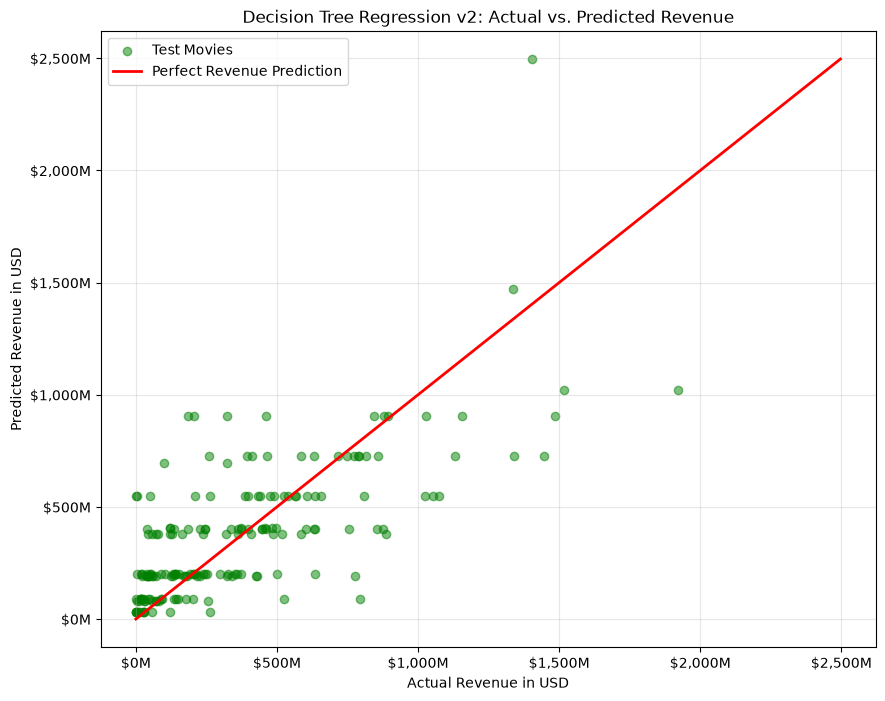

In [22]:
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(ytestingset,pred2,alpha=0.5, color="green",label="Test Movies",)

# draw a diagonal line showing where actual revenue equals predicted revenue
highest2 = max(ytestingset.max(), pred2.max())
plot.plot([0, highest2],[0, highest2],color="red",linewidth=2,label="Perfect Revenue Prediction",)

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)
plot.xlabel("Actual Revenue in USD")
plot.ylabel("Predicted Revenue in USD")
plot.title("Decision Tree Regression v2: Actual vs. Predicted Revenue")
plot.legend()
plot.grid(True, alpha=0.3)
plot.show()

### **Step 4 - Export Data for the Website**

Finally, I generate revenue predictions across all 902 movies using the unscaled features and export everything to `decisiontree_v2.json` in the exact same format as `linearregression_v2.json` so the portfolio website can compare them side by side.

In [25]:
# predict revenue for all 902 movies
everyprediction2 = model2.predict(movies[features])
allmovies2 = []

for i in range(len(movies)):
  iD = movies.iloc[i]
  pred = float(everyprediction2[i])
  actual = float(iD["revenue"])

  if iD.name in xtestingset.index:splitlabel = "Testing"
  else:splitlabel = "Training"

  allmovies2.append({
      "title": str(iD["title"]),
      "split": splitlabel,
      "budget": round(float(iD["budget"]), 0),
      "averageRating": round(float(iD["averageRating"]), 1),
      "numVotes": int(iD["numVotes"]),
      "actualrevenue": round(actual, 0),
      "predictedrevenue": round(pred, 0),
      "difference": round(actual - pred, 0),
  })

export2 = {
    "Model": "Decision Tree V2",
    "Features": features,
    "MaxDepth": int(model2.get_depth()),
    "Leaves": int(model2.get_n_leaves()),
    "MAE": round(float(mae2), 2),
    "RMSE": round(float(rmse2), 2),
    "R2": round(float(r22), 4),
    "R2_percentage": round(float(r22) * 100, 1),
    "movies": allmovies2,
}

with open("decisiontree_v2.json", "w") as file:
  json.dump(export2, file, indent=4)



# **Random Forest Regression V2 - Movie Revenue**

Finally, It is time to train a **Random Forest Regressor V2** using the exact same three input features (`budget`, `averageRating`, and `numVotes`) and the same 80/20 train/test split (`random_state=42`). Instead of relying on a single Decision Tree, this model builds **200 individual Decision Trees** on random subsets of the training movies and averages their predictions together.

### **Step 1 - Tuning & Model Training**

With three features available, deeper trees can capture useful combinations—such as high production budget paired with strong IMDb vote counts and high ratings—without immediately overfitting. I test `max_depth` values from `2` to `10` across a 200-tree forest to find the depth with the highest unseen Test $R^2$, then train the final `model3`.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# variables to keep track of the best depth and best score
bestdepth3 = 2
bestr23 = -9999

#list of tree depths to test
depths = [2, 3, 4, 5, 6, 7, 8, 9, 10]

for depth in depths:
  #create and train a random forest with 200 trees at the current depth
  testforest = RandomForestRegressor(
      n_estimators=200, max_depth=depth, random_state=42
  )
  testforest.fit(xtrainingset, ytrainingset)

  # calculate R2 on both training and testing sets
  trainr2 = testforest.score(xtrainingset, ytrainingset)
  testr2 = testforest.score(xtestingset, ytestingset)

  #print the r2 of test and train for each depth
  print("Depth:",depth,"| Train R2:",round(trainr2, 4),"| Test R2:",round(testr2, 4),)

  # save this depth if it beats our best test score so far
  if testr2 > bestr23:
    bestr23 = testr2
    bestdepth3 = depth

print()
print("Best depth:", bestdepth3, "| Highest Test R2:", round(bestr23, 4))

#train the final Random Forest v2 model using the best depth
model3 = RandomForestRegressor(n_estimators=200, max_depth=bestdepth3, random_state=42)
model3.fit(xtrainingset, ytrainingset);

Depth: 2 | Train R2: 0.4898 | Test R2: 0.4797
Depth: 3 | Train R2: 0.5838 | Test R2: 0.5346
Depth: 4 | Train R2: 0.6425 | Test R2: 0.5485
Depth: 5 | Train R2: 0.7057 | Test R2: 0.5536
Depth: 6 | Train R2: 0.759 | Test R2: 0.5456
Depth: 7 | Train R2: 0.8044 | Test R2: 0.5298
Depth: 8 | Train R2: 0.8411 | Test R2: 0.5177
Depth: 9 | Train R2: 0.8705 | Test R2: 0.5121
Depth: 10 | Train R2: 0.8906 | Test R2: 0.5038

Best depth: 5 | Highest Test R2: 0.5536


### **Step 2 - Evaluation & Feature Importance**

I evaluate the trained Random Forest V2 on the 181 unseen testing movies using **MAE**, **RMSE**, and **$R^2$**, and check how heavily the 200 trees relied on `budget`, `averageRating`, and `numVotes` when making their predictions.

In [ ]:
#generate predictions on the unseen test set
pred3 = model3.predict(xtestingset)

#calculate accuracy metrics
mae3 = mean_absolute_error(ytestingset, pred3)
rmse3 = np.sqrt(mean_squared_error(ytestingset, pred3))
r23 = r2_score(ytestingset, pred3)

#print how much each feature contributed across the 200 trees
print("Importance:")
for i in range(len(features)):
  featurename = features[i]
  importance = round(model3.feature_importances_[i] * 100, 1)
  print(featurename + ":", str(importance) + "%")

print()
print("RMSE: $" + f"{rmse3:,.2f}")
print("MAE:  $" + f"{mae3:,.2f}")
print("R2:  ", round(r23, 4))
print("Trees in Forest:", model3.n_estimators)
print("Max Tree Depth: ", bestdepth3)


Importance:
budget: 67.5%
averageRating: 7.9%
numVotes: 24.7%

RMSE: $243,811,790.63
MAE:  $167,544,155.44
R2:   0.5536
Trees in Forest: 200
Max Tree Depth:  5


### **Step 3 - Visualising Predictions**

I now plot **Actual Revenue vs. Predicted Revenue** for the 181 test movies.

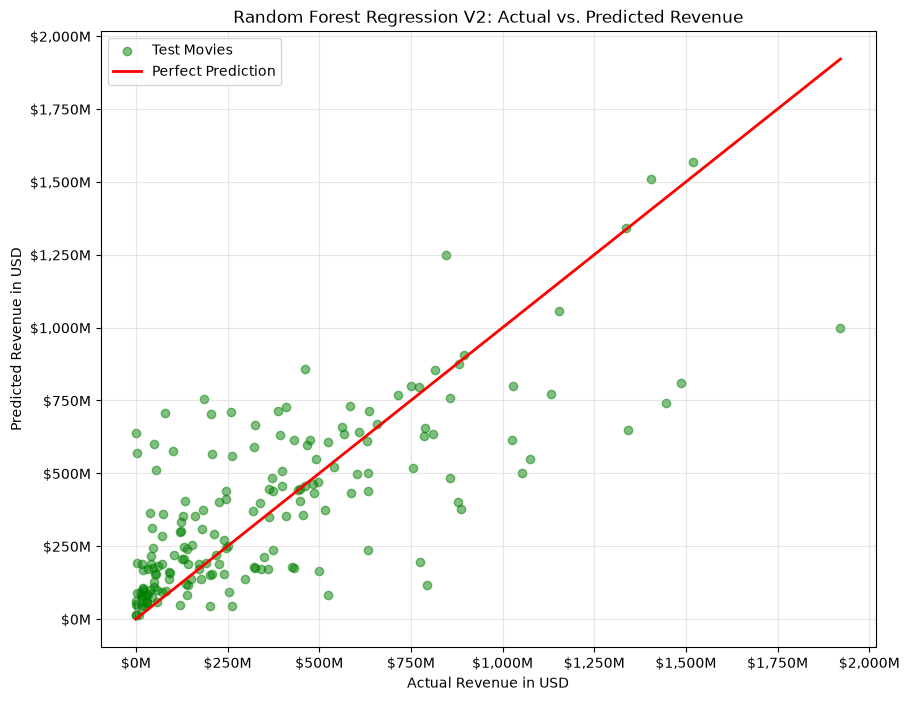

In [34]:
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(ytestingset,pred3,alpha=0.5,color="green",label="Test Movies",)

# draw a diagonal line showing where actual revenue equals predicted revenue
highestvalue = max(ytestingset.max(), pred3.max())
plot.plot([0, highestvalue],[0, highestvalue],label="Perfect Prediction",color="red",linewidth=2,)

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)
plot.xlabel("Actual Revenue in USD")
plot.ylabel("Predicted Revenue in USD")
plot.title("Random Forest Regression V2: Actual vs. Predicted Revenue")
plot.legend()
plot.grid(True, alpha=0.3)
plot.show()

### **Step 4 - Export Data for the Website**

Finally, I generate revenue predictions across all 902 movies using the unscaled features and export everything to `randomforest_v2.json` in the exact same format as `linearregression_v2.json` and `decisiontree_v2.json` so the portfolio website can compare all six models side by side.

In [35]:
# predict revenue for all 902 movies
everyprediction3 = model3.predict(movies[features])
allmovies3 = []

for i in range(len(movies)):
  iD = movies.iloc[i]
  pred = float(everyprediction3[i])
  actual = float(iD["revenue"])
  if iD.name in xtestingset.index:
    splitlabel = "Testing"
  else:
    splitlabel = "Training"

  allmovies3.append({
      "title": str(iD["title"]),
      "split": splitlabel,
      "budget": round(float(iD["budget"]), 0),
      "averageRating": round(float(iD["averageRating"]), 1),
      "numVotes": int(iD["numVotes"]),
      "actualrevenue": round(actual, 0),
      "predictedrevenue": round(pred, 0),
      "difference": round(actual - pred, 0),
  })

export3 = {
    "Model": "Random Forest Regression V2",
    "Features": features,
    "Estimators": int(model3.n_estimators),
    "MaxDepth": int(bestdepth3),
    "MAE": round(float(mae3), 2),
    "RMSE": round(float(rmse3), 2),
    "R2": round(float(r23), 4),
    "R2_percentage": round(float(r23) * 100, 1),
    "movies": allmovies3,
}

with open("randomforest_v2.json", "w") as file:
  json.dump(export3, file, indent=4)

print("Saved randomforest_v2.json successfully!")

Saved randomforest_v2.json successfully!
